# <font color=darkred>Laboratory 19: Sampling and Simulations</font>

## Full name:Dante Valenzuela 
## R#: 12097254
## Title of the notebook: Sampling and Simulations 
## Date: 11/13/26
___

In [3]:
# Preamble script block to identify host, user, and kernel
import sys
! hostname
! whoami
print(sys.executable)
print(sys.version)
print(sys.version_info)

zsh:1: command not found: hostname
jojo
/home/jojo/anaconda3/bin/python
3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:37:38) [GCC 14.3.0]
sys.version_info(major=3, minor=14, micro=6, releaselevel='final', serial=0)


# Simulations
Simulations are used in everything from medical research to fashion and rocket launches. However, we're going to start with a few very basic simulations — but the fundamental principles remain the same! To write a simulation, we need to identify all the factors that might influence the outcome and write Python code to simulate each of these factors.

##  Simple Simulations in Python
The goal of the code we will develop is to store the results of every run of our simulation in a DataFrame. By storing the data in a DataFrame, we can use all the tools and techniques we already know to:

- Select a subset of rows.
- Group data.
- Find descriptive statistics.
- And more!

Almost all simulations will follow a similar "pattern," with only a few select areas needing modification to solve a variety of different problems.

### Simulation Pattern

Every simulation we write will follow a six-step pattern:

1. **Create an Empty List**
   - We will start by creating an initially empty Python list called `data` to accumulate each run of our simulation. This will always be:
     ```python
     data = []
     ```

2. **Write a For-Loop**
   - We will write a for-loop to execute a block of code for each run of our simulation. For a 10,000-run simulation, the loop will look like this:
     ```python
     for i in range(10000):
     ```

3. **Simulate Real-World Factors**
   - Inside the for-loop, we will simulate all real-world factors. For example, in a simple simulation of a six-sided die roll, the code will be:
     ```python
     roll = random.randint(1, 6)
     ```

4. **Accumulate Results in a Dictionary**
   - Inside the for-loop, we will store the simulated factors in a Python dictionary called `d`. A dictionary consists of key-value pairs enclosed in curly braces `{}` and separated by commas. The key in the dictionary will match the name of the real-world factor, enclosed in quotes.
   
   - For example:
     - For a single real-world variable `roll`:
       ```python
       d = { "roll": roll }
       ```
     - For two real-world variables `red` and `blue`:
       ```python
       d = { "red": red, "blue": blue }
       ```
     - For a real-world variable `height`:
       ```python
       d = { "height": height }
       ```
     - For two real-world variables `one` and `two`:
       ```python
       d = { "one": one, "two": two }
       ```

   - We always refer to the variable by its name, which helps in creating columns in our DataFrame with these variable names.

5. **Append the Dictionary to the List**
   - Inside the for-loop, we will append each dictionary `d` to our `data` list. This will always be:
     ```python
     data.append(d)
     ```

6. **Save the Data as a DataFrame**
   - Finally, outside the for-loop, we will convert our `data` list into a DataFrame using `pandas`. This will always be:
     ```python
     df = pd.DataFrame(data)
     ```

   - This step creates a DataFrame from the list of dictionaries, allowing us to analyze and manipulate the simulation results.
### Simulation Example

> #### In 2010, the American Civil Liberties Union (ACLU) of Northern California presented a report on jury selection model in Alameda County, California. The report concluded that certain ethnic groups are underrepresented among jury panelists in Alameda County, and suggested some reforms of the process by which eligible jurors are assigned to panels. 

| Ethnicity | Eligible | Panel |
|-----------|----------|-------|
| Asian     | 0.15     | 0.26  |
| Black     | 0.18     | 0.08  |
| Latino    | 0.12     | 0.08  |
| White     | 0.54     | 0.54  |
| Other     | 0.01     | 0.04  |

### We will perform a simulation of the data given below and examine whether there was truly an underrepresentation of certain groups.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# Model data for jury selection
raw_data = {
    'Ethnicity': ['Asian', 'Black', 'Latino', 'White', 'Other'],
    'Eligible' : [0.15, 0.18, 0.12, 0.54, 0.01],
    'Panel': [0.26, 0.08, 0.08, 0.54, 0.04]
}
df = pd.DataFrame(raw_data)
df

,Ethnicity,Eligible,Panel
0,Asian,0.15,0.26
1,Black,0.18,0.08
2,Latino,0.12,0.08
3,White,0.54,0.54
4,Other,0.01,0.04


<Axes: ylabel='Ethnicity'>

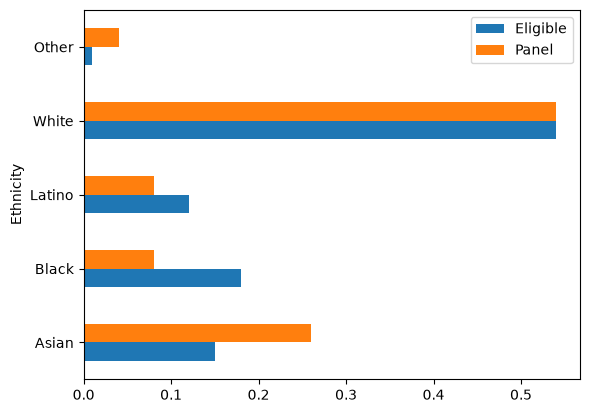

In [6]:
#Plotting horizontal bar chart for 'Eligible' and 'Panel' columns 
df.plot.barh(x='Ethnicity', y=['Eligible', 'Panel'])

In [7]:
#Appending a new column 'EP Difference' with the absolute difference between eligible and panel proportions
df['EP Difference'] = (df['Eligible'] - df['Panel']).abs()
df

,Ethnicity,Eligible,Panel,EP Difference
0,Asian,0.15,0.26,0.11
1,Black,0.18,0.08,0.10
2,Latino,0.12,0.08,0.04
3,White,0.54,0.54,0.00
4,Other,0.01,0.04,0.03


In [8]:
#Computing the observed statistic which is the total variation distance between eligible and panel proportions
observed_total_variance = df['EP Difference'].sum()/2
observed_total_variance

np.float64(0.14)

In [9]:
#Randomly picking one sample of size 1453
#Calculating the total variation distance between random proportions and eligible proportions
groups = df['Ethnicity']
total = 1453
prop = df['Eligible']
random_outcomes = np.random.choice(groups, total, p=prop)
asian_count = np.count_nonzero(random_outcomes=='Asian')
black_count = np.count_nonzero(random_outcomes=='Black')
latino_count = np.count_nonzero(random_outcomes=='Latino')
white_count = np.count_nonzero(random_outcomes=='White')
other_count = np.count_nonzero(random_outcomes=='Other')
sample_prop = np.array([asian_count, black_count, latino_count, white_count, other_count])/total
sample_prop

array([0.14934618, 0.19683414, 0.11975224, 0.52443221, 0.00963524])

In [10]:
#Appending a new column 'Random Sample Panel' with the random sample proportions
df['Random Sample Panel'] = sample_prop
df

,Ethnicity,Eligible,Panel,EP Difference,Random Sample Panel
0,Asian,0.15,0.26,0.11,0.149346
1,Black,0.18,0.08,0.10,0.196834
2,Latino,0.12,0.08,0.04,0.119752
3,White,0.54,0.54,0.00,0.524432
4,Other,0.01,0.04,0.03,0.009635


In [11]:
#Appending a new column 'Random Sample Panel' with the random sample proportions
df['Random Sample Panel'] = sample_prop
df

,Ethnicity,Eligible,Panel,EP Difference,Random Sample Panel
0,Asian,0.15,0.26,0.11,0.149346
1,Black,0.18,0.08,0.10,0.196834
2,Latino,0.12,0.08,0.04,0.119752
3,White,0.54,0.54,0.00,0.524432
4,Other,0.01,0.04,0.03,0.009635


In [12]:
#Appending a new column 'ER Difference' with the absolute difference between eligible and random proportions
df['ER Difference'] = (df['Eligible'] - df['Random Sample Panel']).abs()
df

,Ethnicity,Eligible,Panel,EP Difference,Random Sample Panel,ER Difference
0,Asian,0.15,0.26,0.11,0.149346,0.000654
1,Black,0.18,0.08,0.10,0.196834,0.016834
2,Latino,0.12,0.08,0.04,0.119752,0.000248
3,White,0.54,0.54,0.00,0.524432,0.015568
4,Other,0.01,0.04,0.03,0.009635,0.000365


In [13]:
#Computing the test statistic which is the total variation distance between eligible and random proportions for one sample
sample_total_variance = df['ER Difference'].sum() / 2
sample_total_variance

np.float64(0.016834136269786665)

In [14]:
#Performing simulation by picking 10,000 random samples of size 1453
#Calculating the total variation distance for each of the 10,000 samples
repetitions = 10000
outcomes = []
for i in np.arange(repetitions):
    random_outcomes = np.random.choice(groups, total, p=prop)
    asian_count = np.count_nonzero(random_outcomes=='Asian')
    black_count = np.count_nonzero(random_outcomes=='Black')
    latino_count = np.count_nonzero(random_outcomes=='Latino')
    white_count = np.count_nonzero(random_outcomes=='White')
    other_count = np.count_nonzero(random_outcomes=='Other')

    sample_prop = np.array([asian_count, black_count, latino_count, white_count, other_count])/total
    
    df['Random Sample Panel'] = sample_prop
    sample_dist = ((df['Eligible'] - df['Random Sample Panel']).abs().sum())/2
    outcomes.append(sample_dist)
    
outcomes = np.array(outcomes)

Text(0.5, 1.0, 'Sampling distribution of total variation distance for 10,000 samples of size 1453')

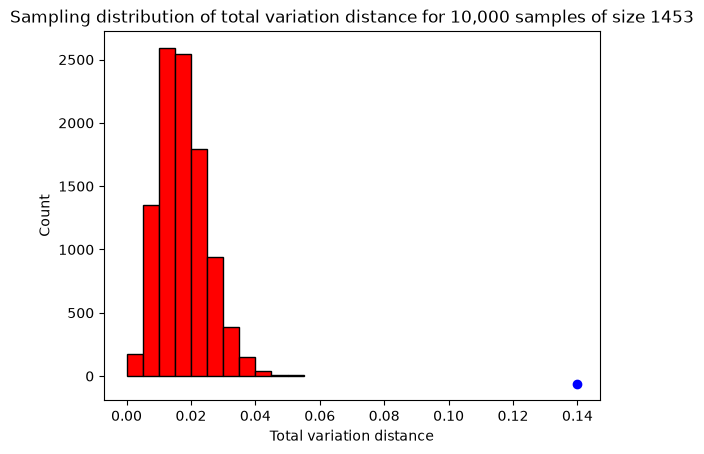

In [15]:
#Plotting a distribution of the test statistic which is the total variation distance along with the observed statistic

plt.hist(outcomes, color='red', ec = 'black', bins=np.arange(0, 0.06, 0.005))
plt.scatter(observed_total_variance, -60, color='blue')
plt.xlabel('Total variation distance')
plt.ylabel('Count')
plt.title('Sampling distribution of total variation distance for 10,000 samples of size 1453')

### Deterministic/Convenience Sampling

One sampling methodology, which is **generally a bad idea**, is to use convenience sampling. For example, you might choose students from your own department or faculty because it is easier to survey them. This approach is known as *convenience sampling* and is considered less rigorous.
#### Code Example
Here’s a simple Python example to illustrate convenience sampling:
```python
import pandas as pd

# Sample data: A DataFrame of students from different faculties
data = {
    'Student': ['Alice', 'Bob', 'Charlie', 'David', 'Eva'],
    'Faculty': ['Science', 'Arts', 'Science', 'Arts', 'Science']
}
df = pd.DataFrame(data)
# Convenience sampling: Selecting only students from the 'Science' faculty
convenience_sample = df[df['Faculty'] == 'Science']

___
### Exercise 17.0 (50 marks)

**Question 1.** Using Pandas DataFrame to read the `player_data.csv` file, store the data into a variable called `full_data` and populate last few rows to the screen

In [16]:
full_data = pd.read_csv('player_data.csv')
full_data.tail()


,Name,Age,Team,Salary
487,Adreian Payne,23,TOT,29843
488,Ricky Ledo,22,TOT,29843
489,Gary Harris,20,DEN,29843
490,Zach LaVine,19,MIN,29843
491,Lance Stephenson,24,CHO,14409



**Question 2**  Assign `convenience_sample_data` to a subset of `full_data` that contains only the rows for players under the age of 22. Reset the index and populate the last few rows to the screen.

In [17]:
convenience_sample_data = full_data[full_data['Age'] < 22].reset_index(drop=True)
convenience_sample_data.tail()

,Name,Age,Team,Salary
39,Julius Randle,20,LAL,150591
40,Tyler Ennis,20,TOT,57711
41,Johnny O'Bryant,21,MIL,35000
42,Gary Harris,20,DEN,29843
43,Zach LaVine,19,MIN,29843


**Question 3.** Compute and assign `convenience_age` and `convenience_salary` to the average age and average salary of your convenience sample.  Since they're computed on a sample, these are called *sample averages*.

In [18]:
convenience_age = round(convenience_sample_data['Age'].mean(),0)
convenience_salary = round(convenience_sample_data['Salary'].mean(),2)

print(convenience_age)
print(convenience_salary)

20.0
2878411.0


**Question 4.** Compute and assign `avg_age` and `avg_salary` to the average age and average salary of your `full_data`. 

In [19]:
avg_age = round(full_data['Age'].mean(),0)
avg_salary = round(full_data['Salary'].mean(),2)

**Question 5.** Does the convenience sample give us an accurate picture of the age and salary of the full population of NBA players in 2014-2015?  Would you expect it to, in general?  Before you move on, write a short answer in English below.  You can refer to the statistics calculated above or perform your own analysis.

i dont think the convenience sample give us an accurate picture of age and salary of the NBA population. Yes there is a lot of younger
people in the NBA but when it comes to salary i believe time and experince makes that go higher and also there is more variabe at play 
than what we have like sponserships and stuff like that that would affect salary. 

___
### Simple random sampling
Simple random sampling is a fundamental technique in statistics where every member of a population has an equal chance of being selected. This method helps to ensure that the sample is representative of the population.
#### Code Example
Here’s a Python example of simple random sampling using the `random` library:
```python
import pandas as pd
import random
# Sample data: A DataFrame of students from different faculties
data = {
    'Student': ['Alice', 'Bob', 'Charlie', 'David', 'Eva'],
    'Faculty': ['Science', 'Arts', 'Science', 'Arts', 'Science']
}
df = pd.DataFrame(data)
# Simple random sampling: Select 2 students randomly from the DataFrame
sample_size = 2
random_sample = df.sample(n=sample_size, random_state=1)
print(random_sample)


### Exercise 17.1  (50 Marks)
**Question 6.** Produce a simple random sample of size 44 from `full_data`. Compute the sample averages (salary and age) again.  Are your results similar to `full_data` age and salary averages?  Run your code several times to get new samples.  How much do things change across samples?

In [72]:
sample_size = 44
random_sample = full_data.sample(n=sample_size)
print(random_sample)


                   Name  Age Team    Salary
410       Nazr Mohammed   37  CHI    816482
238        Mike Muscala   23  ATL   2524200
416      Malcolm Thomas   26  PHI    816482
158        Kosta Koufos   25  MEM   4500000
439      Doug McDermott   23  CHI    507336
326        Phil Pressey   23  BOS   1302840
23       Draymond Green   24  GSW  14898938
169     Marco Belinelli   28  SAS   4000000
412    Kendrick Perkins   30  TOT    816482
95           David West   34  IND   7070730
449    Cameron Bairstow   24  CHI    507336
173         Lavoy Allen   25  IND   3898692
348         Ricky Rubio   24  MIN   1112280
243       Brian Roberts   29  CHO   2421000
346      Shabazz Napier   23  MIA   1127400
129       Trevor Booker   27  UTA   5450000
259        Kyle O'Quinn   24  ORL   2077000
119         Jae Crowder   24  TOT   5871309
176      Mario Chalmers   28  MIA   3867282
368     Anthony Bennett   21  MIN    981084
72         Andrew Bogut   30  GSW   9000000
115      Rodney Stuckey   28  IN

In [73]:
sample_avg_age = round(random_sample['Age'].mean(),0)
sample_avg_salary = round(random_sample['Salary'].mean(),2)
print(sample_avg_age)
print(sample_avg_salary)

28.0
4462456.2


In [ ]:
yes the results are are similar to those of full data the only thing that chages is the avergaes ever so slightly with our sample size
being smaller we get a much smaller variation of averages.

**Question 7** As in the previous question, analyze several simple random samples of size 100 from `full_data`.  Do the average and histogram statistics seem to change more or less across samples of this size than across samples of size 44?  And are the sample averages and histograms closer to their true values (`full_data` averages) for age or for salary?  What did you expect to see?

In [66]:
sample_size=100 
random_sample = full_data.sample(n=sample_size)
sample_avg_age = round(random_sample['Age'].mean(),0)
sample_avg_salary = round(random_sample['Salary'].mean(),2)

In [67]:
print(sample_avg_age)
print(sample_avg_salary)

27.0
4436763.61


In [74]:
The averages change less because of our sample size being larger. With our sample size beig 100 we get a beter average of age and salary
than we do with a sample size of just 44. with a higher sample size a histogram would more accurately center the average than it would 
with a smaller sample size.

SyntaxError: invalid syntax (3670347270.py, line 1)

**Question 8.** Repeat process in **Question 6** and **Question 7** using sample with replacement technique, then analyze any difference from prior results

In [79]:
sample_44 = full_data.sample(n=44, replace = True)
print(round(sample_44['Age'].mean(),2))
print(round(sample_44['Salary'].mean(),2))

27.07
4025815.52


In [80]:
sample_100 = full_data.sample(n=100, replace = True)
print(round(sample_100['Age'].mean(),2))
print(round(sample_100['Salary'].mean(),2))

26.31
4694293.73


array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Salary'}>]], dtype=object)

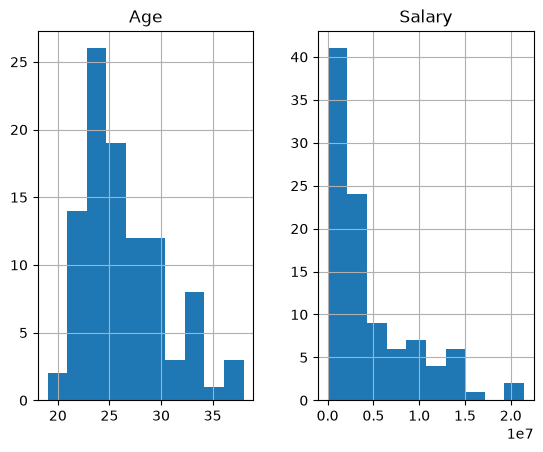

In [81]:
sample_100[['Age', 'Salary']].hist()

array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Salary'}>]], dtype=object)

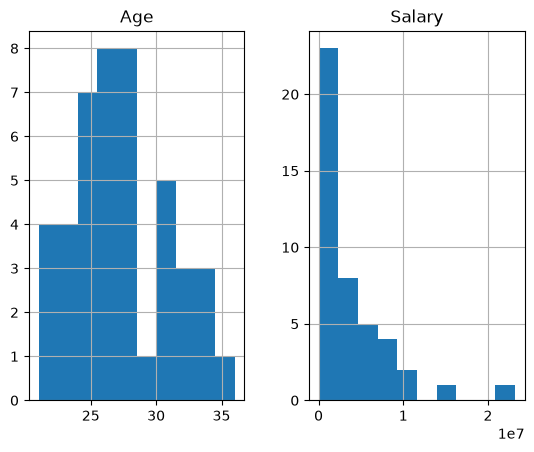

In [82]:
sample_44[['Age','Salary']].hist()

**Question 9.** Simulate and plot **without replacement** the Average Salary and Age of 100 samples 

array([[<Axes: title={'center': 'Avg Age'}>,
        <Axes: title={'center': 'Avg Salary'}>]], dtype=object)

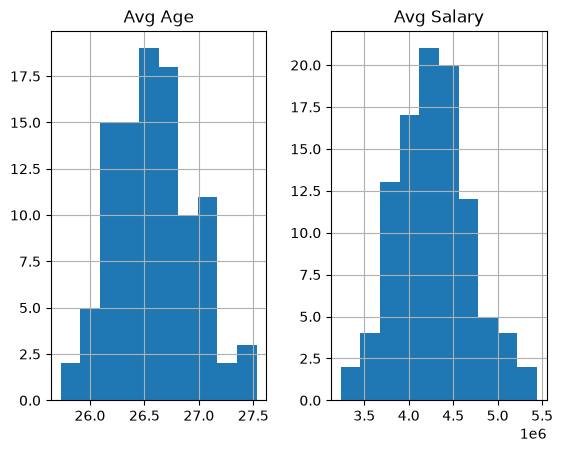

In [88]:
samples = 100
size = 100

avg_age = []
avg_salary = []

for i in range(samples):
    sample_df = full_data.sample(n=size, replace = False)

    avg_age.append(sample_df['Age'].mean())
    avg_salary.append(sample_df['Salary'].mean())

result = pd.DataFrame({'Avg Age':avg_age,
                       'Avg Salary':avg_salary
                      })
result.hist()

**Question 10.** Simulate and plot **replacement** the Average Salary and Age of 100 samples 

array([[<Axes: title={'center': 'Avg Age'}>,
        <Axes: title={'center': 'Avg Salary'}>]], dtype=object)

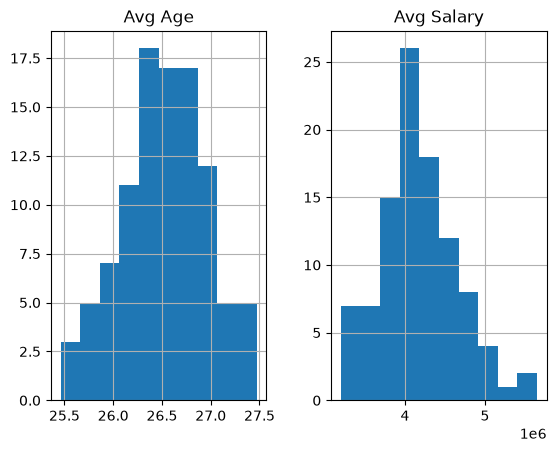

In [87]:
samples = 100
size = 100

avg_age = []
avg_salary = []

for i in range(samples):
    sample_df = full_data.sample(n=size, replace = True)

    avg_age.append(sample_df['Age'].mean())
    avg_salary.append(sample_df['Salary'].mean())

result = pd.DataFrame({'Avg Age':avg_age,
                       'Avg Salary':avg_salary
                      })
result.hist()